## Лабораторная работа 5. Теплопроводность с переносом
Найти $T(x,t)$: $c\rho T_t=\lambda T_{xx}-vT_x$, $0<x<\ell$.
$\lambda T_x(0,t)=\alpha_1(T(0,t)-T_1(t))$,
$-\lambda T_x(\ell,t)=\alpha_2(T(\ell,t)-T_2(t))$, $T(x,0)=T_0(x)$.
На фото нет численных данных. Учебный пример в условных единицах:
$c=\rho=\lambda=\ell=v=1$, $\alpha_1=\alpha_2=2$, $T_1=20$, $T_2=T_0=0$.
Сжатая реализация: диффузия неявная, перенос явный, прогонка без своих функций.


In [1]:
import numpy as np; import matplotlib.pyplot as plt
from pathlib import Path
root = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
out = root/'results'; out.mkdir(parents=True, exist_ok=True)
c, rho, lam, ell, v = 1., 1., 1., 1., 1.
alpha1, alpha2 = 2., 2.; t_end = 2.; N = 80; M = 2000
h = ell/N; tau = t_end/M; x = np.linspace(0, ell, N+1); t = np.linspace(0, t_end, M+1)
T1 = np.full(M+1, 20.); T2 = np.zeros(M+1); u = np.zeros((M+1, N+1))  # u[0] = T0(x)
r = c*rho*h*h/(lam*tau); g = v*h/lam; s1 = alpha1*h/lam; s2 = alpha2*h/lam
assert N >= 2 and M > 0 and min(c, rho, lam, ell, t_end) > 0 and min(v, alpha1, alpha2) >= 0
assert 2*v*tau/(c*rho*h) <= 1, 'Уменьшите tau: явный перенос требует 2*v*tau/(c*rho*h) <= 1'


### Схема с фотографии и прогонка
$r(y_i-z_i)=y_{i+1}-2y_i+y_{i-1}-g(z_i-z_{i-1})$, $1\le i<N$.
$\frac r2(y_0-z_0)=y_1-y_0-s_1(y_0-T_1)$.
$\frac r2(y_N-z_N)=y_{N-1}-y_N-s_2(y_N-T_2)-g(z_N-z_{N-1})$.
Здесь $y=u^{j+1}$, $z=u^j$, $s_k=\alpha_k h/\lambda$; на доске в $\bar\alpha_k$ пропущен $h$.
На правой границе полный множитель $g$, на левой переноса нет — как в системе (2) на фото.


In [2]:
a = -np.ones(N); b = np.r_[r/2+1+s1, np.full(N-1, r+2), r/2+1+s2]; upper = -np.ones(N)
residual = np.zeros(M); direct_error = 0.
for j in range(M):
    rhs = np.r_[r*u[j,0]/2+s1*T1[j+1], r*u[j,1:-1]-g*np.diff(u[j,:-1]),
                r*u[j,-1]/2-g*(u[j,-1]-u[j,-2])+s2*T2[j+1]]
    p = np.zeros(N); q = np.zeros(N+1); p[0] = upper[0]/b[0]; q[0] = rhs[0]/b[0]
    for i in range(1, N+1):
        z = b[i]-a[i-1]*p[i-1]
        if i < N: p[i] = upper[i]/z
        q[i] = (rhs[i]-a[i-1]*q[i-1])/z
    u[j+1,-1] = q[-1]
    for i in range(N-1, -1, -1): u[j+1,i] = q[i]-p[i]*u[j+1,i+1]
    defect = b*u[j+1]-rhs; defect[1:] += a*u[j+1,:-1]; defect[:-1] += upper*u[j+1,1:]
    residual[j] = np.max(np.abs(defect))
    if j in (0, M-1):
        direct = np.linalg.solve(np.diag(b)+np.diag(a,-1)+np.diag(upper,1), rhs)
        direct_error = max(direct_error, np.max(np.abs(direct-u[j+1])))
assert np.isfinite(u).all() and residual.max() < 1e-9 and direct_error < 1e-9
assert u.min() >= min(u[0].min(), T1.min(), T2.min())-1e-9 and u.max() <= max(u[0].max(), T1.max(), T2.max())+1e-9


### Проверка стационарного решения
При постоянных данных $T_\infty=A+B e^{vx/\lambda}$; коэффициенты определяются условиями Робина.
При $v=0$: $T_\infty=A+Bx$. Сравниваем также со стационарным решением самой сеточной схемы.


In [3]:
assert np.all(T1 == T1[0]) and np.all(T2 == T2[0]), 'Стационарная проверка рассчитана на постоянные T1, T2'
assert alpha1+alpha2 > 0, 'Для однозначного стационара задайте хотя бы один alpha > 0'
if v > 0:
    A, B = np.linalg.solve([[alpha1, alpha1-v], [alpha2, (alpha2+v)*np.exp(v*ell/lam)]], [alpha1*T1[0], alpha2*T2[0]])
    exact = A+B*np.exp(v*x/lam)
else:
    A, B = np.linalg.solve([[alpha1, -lam], [alpha2, alpha2*ell+lam]], [alpha1*T1[0], alpha2*T2[0]])
    exact = A+B*x
steady_rhs = np.r_[s1*T1[0], np.zeros(N-1), s2*T2[0]]
steady_matrix = np.diag(np.r_[1+s1, np.full(N-1, 2+g), 1+s2+g])+np.diag(np.full(N, -1-g), -1)+np.diag(upper, 1)
steady = np.linalg.solve(steady_matrix, steady_rhs)
print(f'N={N}, M={M}, h={h:g}, tau={tau:g}; 2*CFL={2*v*tau/(c*rho*h):g}')
print(f'Невязка системы: {residual.max():.2e}; отличие от прямого решения: {direct_error:.2e}')
print(f'Ошибка стационарной схемы: {np.max(np.abs(steady-exact)):.6f}')
print(f'Отклонение при t={t_end:g} от сеточного стационара: {np.max(np.abs(u[-1]-steady)):.6f}')
print(f'Температура при t={t_end:g}: слева {u[-1,0]:.6f}, в центре {u[-1,N//2]:.6f}, справа {u[-1,-1]:.6f}')
steps = np.rint(np.array([0., 0.1, 0.25, 0.5, 1.])*M).astype(int)
np.savez_compressed(out/'heat.npz', x=x, t=t, u=u, exact_stationary=exact, discrete_stationary=steady, residual=residual,
                    c=c, rho=rho, lam=lam, ell=ell, v=v, alpha1=alpha1, alpha2=alpha2, T1=T1, T2=T2)
np.savetxt(out/'temperature.csv', np.column_stack([x, u[steps].T, exact, steady]), delimiter=',',
           header='x,'+','.join(f'T_t{t[j]:g}' for j in steps)+',exact_stationary,discrete_stationary', comments='')


N=80, M=2000, h=0.0125, tau=0.001; 2*CFL=0.16
Невязка системы: 1.42e-14; отличие от прямого решения: 5.33e-15
Ошибка стационарной схемы: 0.020168
Отклонение при t=2 от сеточного стационара: 0.030008
Температура при t=2: слева 17.167398, в центре 13.531509, справа 7.583488


### Графики


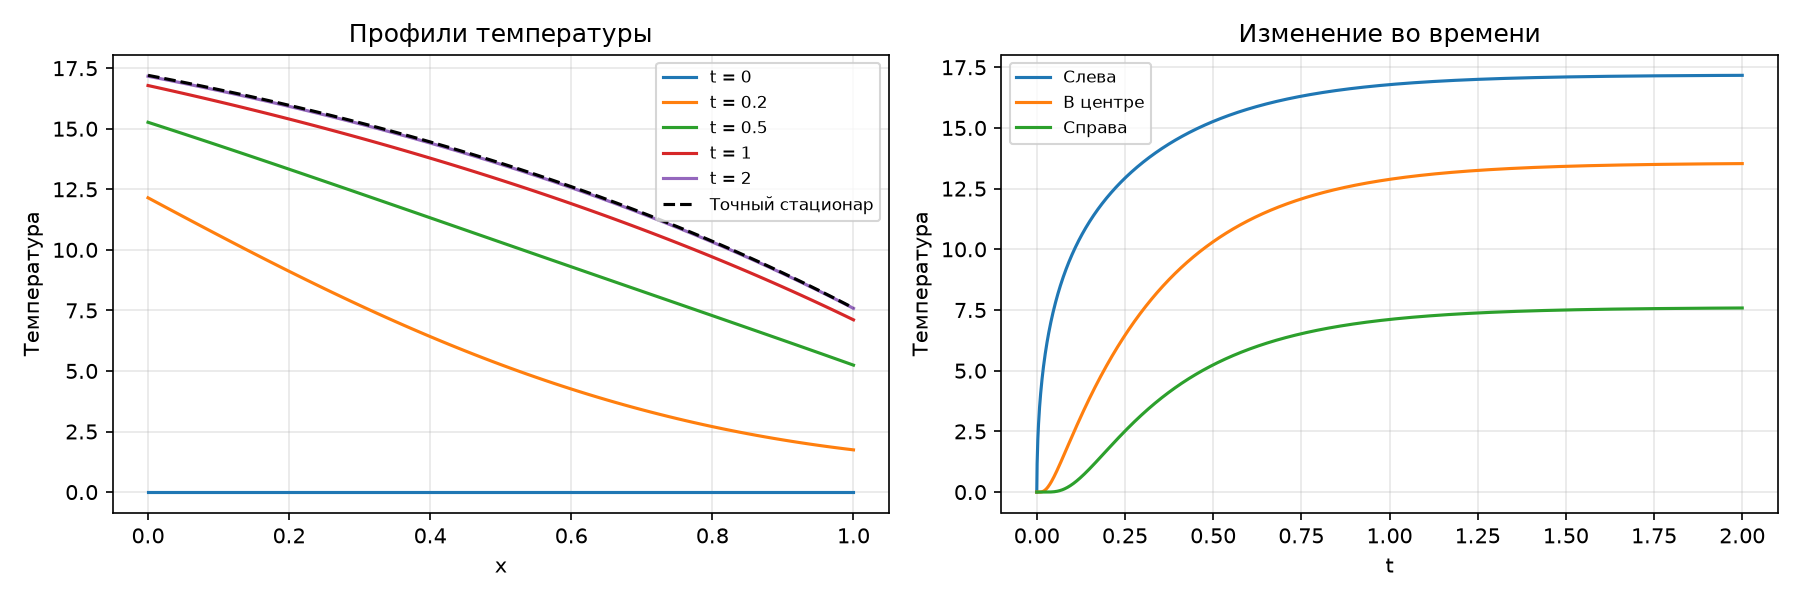

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for j in steps: ax[0].plot(x, u[j], label=f't = {t[j]:g}')
ax[0].plot(x, exact, 'k--', label='Точный стационар'); ax[0].set(xlabel='x', ylabel='Температура', title='Профили температуры')
for i, name in [(0, 'Слева'), (N//2, 'В центре'), (N, 'Справа')]: ax[1].plot(t, u[:,i], label=name)
ax[1].set(xlabel='t', ylabel='Температура', title='Изменение во времени')
for axis in ax: axis.legend(fontsize=8); axis.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(out/'heat.png', dpi=150)
if plt.get_backend().lower() != 'agg': plt.show()


### Вывод
Температура растёт от левой границы, перенос направлен вправо. Решение приближается к стационарному.
При t=2: слева 17.167398, в центре 13.531509, справа 7.583488; стационарная сеточная ошибка 0.020168.
Прогонка совпадает с прямым решением системы; стационарная погрешность уменьшается при сгущении сетки.
Метод имеет первый порядок по времени и пространству; численные результаты — в results/.
